In [ ]:

# Step 1: Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("All libraries imported successfully!")


All libraries imported successfully!


In [ ]:

# Step 2: Load the CSV file

df = pd.read_csv("/content/housing.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [ ]:

# Step 3: Inspect columns, data types, and summary statistics

print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nSummary statistics:")
display(df.describe().T)

print("\nMissing values in each column:")
display(df.isnull().sum())


Column names:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value', 'ocean_proximity']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB

Summary statistics:


,count,mean,std,min,25%,50%,75%,max
longitude,20640.0,-119.569704,2.003532,-124.3500,-121.8000,-118.4900,-118.01000,-114.3100
latitude,20640.0,35.631861,2.135952,32.5400,33.9300,34.2600,37.71000,41.9500
housing_median_age,20640.0,28.639486,12.585558,1.0000,18.0000,29.0000,37.00000,52.0000
total_rooms,20640.0,2635.763081,2181.615252,2.0000,1447.7500,2127.0000,3148.00000,39320.0000
total_bedrooms,20433.0,537.870553,421.385070,1.0000,296.0000,435.0000,647.00000,6445.0000
population,20640.0,1425.476744,1132.462122,3.0000,787.0000,1166.0000,1725.00000,35682.0000
households,20640.0,499.539680,382.329753,1.0000,280.0000,409.0000,605.00000,6082.0000
median_income,20640.0,3.870671,1.899822,0.4999,2.5634,3.5348,4.74325,15.0001
median_house_value,20640.0,206855.816909,115395.615874,14999.0000,119600.0000,179700.0000,264725.00000,500001.0000



Missing values in each column:


,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,207
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0


Duplicate rows: 0
Missing target values: 0


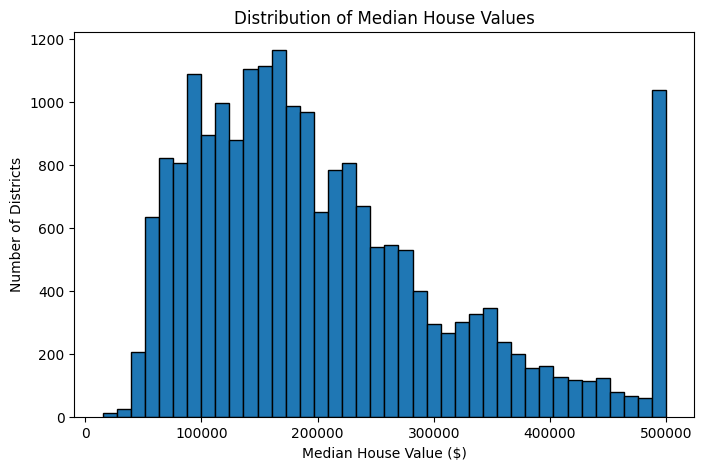

In [ ]:

# Step 4: Check duplicates and target values

print("Duplicate rows:", df.duplicated().sum())
print("Missing target values:", df["median_house_value"].isna().sum())

plt.figure(figsize=(8, 5))
plt.hist(df["median_house_value"], bins=40, edgecolor="black")
plt.xlabel("Median House Value ($)")
plt.ylabel("Number of Districts")
plt.title("Distribution of Median House Values")
plt.show()


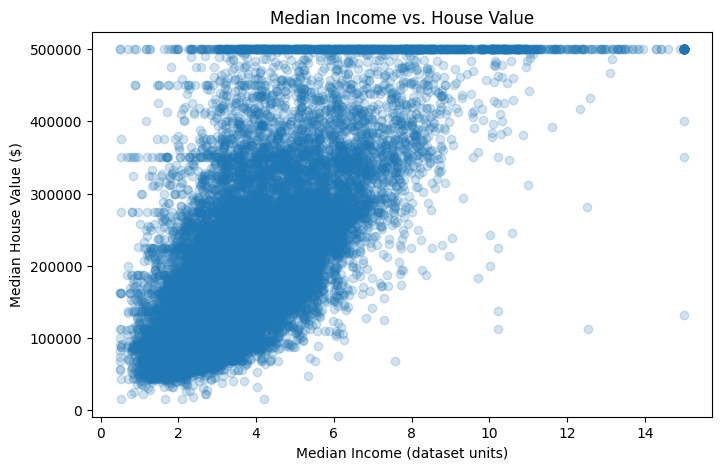

In [ ]:

# Step 5A: Income vs. house value

plt.figure(figsize=(8, 5))
plt.scatter(
    df["median_income"],
    df["median_house_value"],
    alpha=0.2
)
plt.xlabel("Median Income (dataset units)")
plt.ylabel("Median House Value ($)")
plt.title("Median Income vs. House Value")
plt.show()


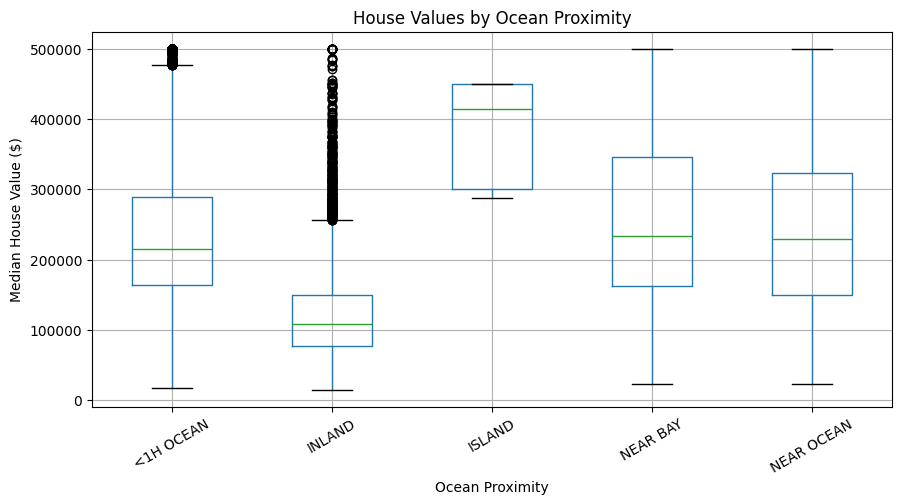

In [ ]:

# Step 5B: House values by ocean proximity

df.boxplot(
    column="median_house_value",
    by="ocean_proximity",
    figsize=(10, 5),
    rot=30
)

plt.title("House Values by Ocean Proximity")
plt.suptitle("")
plt.xlabel("Ocean Proximity")
plt.ylabel("Median House Value ($)")
plt.show()


In [ ]:

# Step 6: Separate input features and target

X = df.drop(columns=["median_house_value"])
y = df["median_house_value"]

numerical_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)
print("Target: median_house_value")


Numerical features: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']
Categorical features: ['ocean_proximity']
Target: median_house_value


In [ ]:

# Step 7: Split into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])


Training records: 16512
Testing records: 4128


In [ ]:

# Step 8: Preprocess numerical and categorical features

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numerical", numerical_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully!")


Preprocessing pipeline created successfully!


In [ ]:

# Step 9: Create and train the models

linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

linear_model.fit(X_train, y_train)
random_forest_model.fit(X_train, y_train)

print("Both models trained successfully!")


Both models trained successfully!


In [ ]:

# Step 10: Evaluate both models

def evaluate_model(name, model, X_test, y_test):
    predictions = model.predict(X_test)

    return {
        "Model": name,
        "MAE ($)": mean_absolute_error(y_test, predictions),
        "RMSE ($)": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2 Score": r2_score(y_test, predictions)
    }

results = pd.DataFrame([
    evaluate_model("Linear Regression", linear_model, X_test, y_test),
    evaluate_model("Random Forest", random_forest_model, X_test, y_test)
])

display(results.round(3))


,Model,MAE ($),RMSE ($),R2 Score
0,Linear Regression,50670.489,70059.193,0.625
1,Random Forest,31628.407,48941.700,0.817


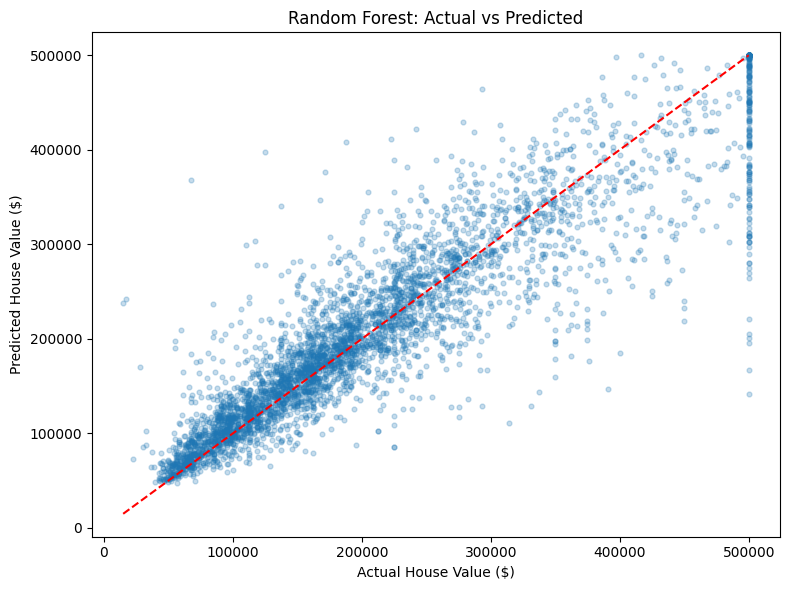

In [ ]:

# Step 11: Compare actual and predicted values

predictions = random_forest_model.predict(X_test)

plt.figure(figsize=(8, 6))
plt.scatter(y_test, predictions, alpha=0.25, s=12)

lower = min(y_test.min(), predictions.min())
upper = max(y_test.max(), predictions.max())

plt.plot([lower, upper], [lower, upper], "r--")
plt.xlabel("Actual House Value ($)")
plt.ylabel("Predicted House Value ($)")
plt.title("Random Forest: Actual vs Predicted")
plt.tight_layout()
plt.show()


In [ ]:

# Step 12: Predict the value for a sample district

sample = X_test.iloc[[0]]
actual_value = y_test.iloc[0]
predicted_value = random_forest_model.predict(sample)[0]

display(sample)

print(f"Actual house value:    ${actual_value:,.2f}")
print(f"Predicted house value: ${predicted_value:,.2f}")
print(f"Absolute error:        ${abs(actual_value - predicted_value):,.2f}")


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity
20046,-119.01,36.06,25.0,1505.0,NaN,1392.0,359.0,1.6812,INLAND


Actual house value:    $47,700.00
Predicted house value: $51,744.00
Absolute error:        $4,044.00


In [ ]:

# Step 13: Save the trained models

import joblib

joblib.dump(linear_model, "/content/linear_regression_model.joblib")
joblib.dump(random_forest_model, "/content/random_forest_model.joblib")

print("Models saved successfully!")


Models saved successfully!


In [ ]:
print("X_train exists:", "X_train" in globals())
print("X_test exists:", "X_test" in globals())
print("linear_model exists:", "linear_model" in globals())
print("random_forest_model exists:", "random_forest_model" in globals())

X_train exists: True
X_test exists: True
linear_model exists: True
random_forest_model exists: True


In [ ]:
import os

print(os.path.exists("/content/housing.csv"))

True


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv("/content/housing.csv")

X = df.drop("median_house_value", axis=1)
y = df["median_house_value"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (16512, 9)
Testing data: (4128, 9)


In [ ]:
import pandas as pd

df = pd.read_csv("/content/housing.csv")

print(df.shape)
print(df.head())

(20640, 10)
   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -122.23     37.88                41.0        880.0           129.0   
1    -122.22     37.86                21.0       7099.0          1106.0   
2    -122.24     37.85                52.0       1467.0           190.0   
3    -122.25     37.85                52.0       1274.0           235.0   
4    -122.25     37.85                52.0       1627.0           280.0   

   population  households  median_income  median_house_value ocean_proximity  
0       322.0       126.0         8.3252            452600.0        NEAR BAY  
1      2401.0      1138.0         8.3014            358500.0        NEAR BAY  
2       496.0       177.0         7.2574            352100.0        NEAR BAY  
3       558.0       219.0         5.6431            341300.0        NEAR BAY  
4       565.0       259.0         3.8462            342200.0        NEAR BAY  


In [ ]:
%pip install -q gradio

In [ ]:
print("Dataset loaded:", "df" in globals())
print("Training data ready:", "X_train" in globals())
print("Linear Regression model ready:", "linear_model" in globals())
print("Random Forest model ready:", "random_forest_model" in globals())

Dataset loaded: True
Training data ready: True
Linear Regression model ready: True
Random Forest model ready: True


In [ ]:
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# Identify numerical and categorical columns
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# Preprocessing for numerical columns
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocessing for categorical columns
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Linear Regression model
linear_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

# Random Forest model
random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# Train both models
print("Training Linear Regression...")
linear_model.fit(X_train, y_train)

print("Training Random Forest...")
random_forest_model.fit(X_train, y_train)

print("Both models trained successfully!")

Training Linear Regression...
Training Random Forest...
Both models trained successfully!


In [ ]:
import gradio as gr

In [ ]:

import gradio as gr
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Confirm that the models are trained
assert "linear_model" in globals(), "Train Linear Regression first."
assert "random_forest_model" in globals(), "Train Random Forest first."

FEATURES = list(X_train.columns)

def predict_house_value(
    model_name,
    longitude,
    latitude,
    housing_median_age,
    total_rooms,
    total_bedrooms,
    population,
    households,
    median_income,
    ocean_proximity
):
    house = pd.DataFrame([{
        "longitude": longitude,
        "latitude": latitude,
        "housing_median_age": housing_median_age,
        "total_rooms": total_rooms,
        "total_bedrooms": total_bedrooms,
        "population": population,
        "households": households,
        "median_income": median_income,
        "ocean_proximity": ocean_proximity
    }])

    house = house[FEATURES]

    if model_name == "Random Forest":
        model = random_forest_model
    else:
        model = linear_model

    predicted_value = float(model.predict(house)[0])

    test_predictions = model.predict(X_test)
    mae = mean_absolute_error(y_test, test_predictions)
    rmse = np.sqrt(mean_squared_error(y_test, test_predictions))
    r2 = r2_score(y_test, test_predictions)

    return (
        f"Estimated median district house value: ${predicted_value:,.0f}\n\n"
        f"Selected model: {model_name}\n"
        f"Test-set MAE: ${mae:,.0f}\n"
        f"Test-set RMSE: ${rmse:,.0f}\n"
        f"Test-set R²: {r2:.3f}\n\n"
        "Note: This is a historical California district-level estimate, "
        "not a current individual-house valuation."
    )


with gr.Blocks(title="House Price Prediction System") as demo:
    gr.Markdown("# 🏡 House Price Prediction System")
    gr.Markdown(
        "Enter district characteristics and select a machine-learning model."
    )
    gr.Markdown(
        "**Dataset:** California Housing Prices | "
        "**Models:** Linear Regression and Random Forest"
    )

    model_choice = gr.Dropdown(
        choices=["Linear Regression", "Random Forest"],
        value="Random Forest",
        label="Select Machine Learning Model"
    )

    with gr.Row():
        longitude = gr.Number(value=-122.23, label="Longitude")
        latitude = gr.Number(value=37.88, label="Latitude")

    with gr.Row():
        housing_median_age = gr.Number(
            value=30, label="Median House Age (years)"
        )
        median_income = gr.Number(
            value=5.0, label="Median Income (dataset units)"
        )

    with gr.Row():
        total_rooms = gr.Number(value=2000, label="Total Rooms")
        total_bedrooms = gr.Number(value=400, label="Total Bedrooms")

    with gr.Row():
        population = gr.Number(value=800, label="Population")
        households = gr.Number(value=300, label="Households")

    ocean_proximity = gr.Dropdown(
        choices=[
            "<1H OCEAN",
            "INLAND",
            "ISLAND",
            "NEAR BAY",
            "NEAR OCEAN"
        ],
        value="NEAR BAY",
        label="Ocean Proximity"
    )

    predict_button = gr.Button(
        "Predict House Value", variant="primary"
    )

    output = gr.Textbox(
        label="Prediction and Model Evaluation",
        lines=8
    )

    predict_button.click(
        fn=predict_house_value,
        inputs=[
            model_choice,
            longitude,
            latitude,
            housing_median_age,
            total_rooms,
            total_bedrooms,
            population,
            households,
            median_income,
            ocean_proximity
        ],
        outputs=output
    )

demo.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://5ae46fdbbfe4821506.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
